# Кейс №23 · Классификация никнеймов Dota 2

Откройте ноутбук в JupyterHub и выберите **Restart Kernel and Run All Cells**.

Ноутбук прочитает две готовые MART на 100 и 200 ответов. Разметка на 300 ключей уже встроена. Она подготовлена по текстам ников без просмотра ответов MART и остаётся черновой до проверки командой.

**H1.** Сравниваем F1 модели и правил по пяти тегам. Критерий выполнен на выборке, если LLM выигрывает хотя бы по одному тегу.

**H2.** Проверяем, выше ли доля поражений у игроков с явно агрессивной лексикой в никах после учёта ранга, режима и повторных матчей аккаунта. Окно матчей исправлено по проверенному диапазону RAW. При недостатке совпадений ноутбук покажет, на каком этапе потерялись данные.

In [1]:
from datetime import datetime
from io import StringIO
from importlib.util import find_spec
from statistics import NormalDist
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter, MaxNLocator
from IPython.display import display

READ_LIVE_MART = find_spec("pyspark") is not None and find_spec("lakehouse_spark") is not None
RUN_OUTCOMES = READ_LIVE_MART

# Параметры проверки. Настройки модели Portal при чтении MART недоступны.
SEED = 23
ALPHA = 0.05
H1_MIN_SHARE = 0.20
BOOTSTRAP_REPEATS = 2_000
MIN_TAG_POSITIVES = 10
MIN_TAG_NEGATIVES = 10
H2_MIN_DIFFERENCE_PP = 0.0
H2_MIN_ACCOUNTS = 30
H2_MIN_MATCHES = 30
H2_MIN_ACCOUNTS_PER_GROUP = 10
WINDOW_START_UTC = "2026-10-14T00:00:00+00:00"
WINDOW_END_UTC = "2026-10-16T00:00:00+00:00"
MATCH_LIMIT = None  # Все матчи в проверенном окне

CLEAN = "lakehouse.stage.case23_nickname_clean1"
MATCHES = "lakehouse.raw.pg__matches"
MATCH_PLAYERS = "lakehouse.raw.pg__match_players"

STAGE = "lakehouse.stage.case23_nickname_unique1"
MART_TABLES = {
    "100 строк": "lakehouse.mart.case23_nickname_1000_b01",
    "200 строк": "lakehouse.mart.case23_nickname_1000_single",
}
TAGS = ("clan_tag", "streamer", "bot", "toxic", "cyrillic")
STATES = ("tagged", "other", "unknown")
plt.rcParams.update({"font.family": "DejaVu Sans", "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titleweight": "bold"})

## Параметры проверки

Пороги и окно задаются до просмотра эффектов. Минимумы по классам и кластерам служат условиями расчёта интервалов. Температура и другие параметры генерации Portal из ответов MART не определяются.

In [2]:
assert 0 < ALPHA < 1 and 0 < H1_MIN_SHARE <= 1
assert BOOTSTRAP_REPEATS > 0 and (MATCH_LIMIT is None or MATCH_LIMIT > 0)
assert min(MIN_TAG_POSITIVES, MIN_TAG_NEGATIVES, H2_MIN_ACCOUNTS,
           H2_MIN_MATCHES, H2_MIN_ACCOUNTS_PER_GROUP) > 0
assert datetime.fromisoformat(WINDOW_START_UTC) < datetime.fromisoformat(WINDOW_END_UTC)
h1_min_tags = int(np.ceil(len(TAGS) * H1_MIN_SHARE))
h1_tail = ALPHA / (2 * len(TAGS))
h2_z = NormalDist().inv_cdf(1 - ALPHA / 2)
display(pd.Series({
    "H1 · минимум тегов с выигрышем": f"{h1_min_tags} из {len(TAGS)} ({H1_MIN_SHARE:.0%})",
    "H1 · уровень доверия для пяти сравнений": f"{1 - ALPHA:.0%}",
    "H1 · границы квантилей для одного тега": f"{h1_tail:.2%} и {1 - h1_tail:.2%}",
    "H1 · парные bootstrap-повторы": BOOTSTRAP_REPEATS,
    "H1 · минимум положительных и отрицательных примеров для интервала":
        f"{MIN_TAG_POSITIVES} и {MIN_TAG_NEGATIVES}",
    "H2 · порог разницы, п. п.": H2_MIN_DIFFERENCE_PP,
    "H2 · уровень доверия и z-коэффициент": f"{1 - ALPHA:.0%} / {h2_z:.3f}",
    "H2 · окно UTC [начало, конец)": f"{WINDOW_START_UTC} → {WINDOW_END_UTC}",
    "H2 · лимит матчей": MATCH_LIMIT if MATCH_LIMIT is not None else "Всё окно",
    "H2 · минимум аккаунтов / матчей / аккаунтов в каждой группе":
        f"{H2_MIN_ACCOUNTS} / {H2_MIN_MATCHES} / {H2_MIN_ACCOUNTS_PER_GROUP}",
    "Seed": SEED,
}, name="Значение").to_frame())

,Значение
H1 · минимум тегов с выигрышем,1 из 5 (20%)
H1 · уровень доверия для пяти сравнений,95%
H1 · границы квантилей для одного тега,0.50% и 99.50%
H1 · парные bootstrap-повторы,2000
H1 · минимум положительных и отрицательных примеров для интервала,10 и 10
"H2 · порог разницы, п. п.",0.0
H2 · уровень доверия и z-коэффициент,95% / 1.960
"H2 · окно UTC [начало, конец)",2026-10-14T00:00:00+00:00 → 2026-10-16T00:00:0...
H2 · лимит матчей,Всё окно
H2 · минимум аккаунтов / матчей / аккаунтов в каждой группе,30 / 30 / 10


## 1. Подготовка данных

CLEAN сохраняет исходные ники и причины исключения. UNIQUE объединяет одинаковые нормализованные строки и присваивает им стабильный SHA‑256 ключ. Ниже приведён проверенный снимок из исходного ноутбука. Для графиков обогащения используются ответы двух MART.

In [3]:
clean_rows, missing_rows, invalid_rows = 1_759_107, 1_287_163, 6_116
valid_rows, unique_nicks = 465_828, 368_041
assert clean_rows == missing_rows + invalid_rows + valid_rows
display(pd.DataFrame({
    "Показатель": ["Записи CLEAN", "Пропуски", "Некорректные", "Валидные",
                   "Уникальные", "Убрано повторов", "Экономия потенциальных вызовов"],
    "Значение": [f"{x:,}".replace(",", " ") for x in (
        clean_rows, missing_rows, invalid_rows, valid_rows, unique_nicks, valid_rows - unique_nicks
    )] + [f"{100 * (valid_rows - unique_nicks) / valid_rows:.2f}%"],
}).set_index("Показатель"))

,Значение
Показатель,
Записи CLEAN,1 759 107
Пропуски,1 287 163
Некорректные,6 116
Валидные,465 828
Уникальные,368 041
Убрано повторов,97 787
Экономия потенциальных вызовов,20.99%


## 2. Ответы из MART

Для каждого запуска выводятся число сохранённых ответов и количество ключей. При чтении Lakehouse проверяются пустые ключи, повторы внутри и между таблицами, связь со STAGE и формат разметки. Конфликтующие записи по одному ключу требуют сверки исходных MART.

В сохранённой сводке проверка пересечения основана на 100 входных ключах первого пакета и хешах текстов 200 ответов второго. При включении READ_LIVE_MART ноутбук сверит фактические ключи обоих MART.

In [4]:
def aggregate_answers(frame):
    by_run = frame.groupby("Пакет", sort=False)
    counts = by_run["nickname_key"].size().rename("Ответы").to_frame()
    counts["На ручной проверке"] = by_run["review_flag"].sum()
    states = pd.crosstab(frame["Пакет"], frame["state"]).reindex(
        index=counts.index, columns=STATES, fill_value=0
    )
    tags = frame[["Пакет", "tag_list"]].explode("tag_list")
    tag_counts = pd.crosstab(tags["Пакет"], tags["tag_list"]).reindex(
        index=counts.index, columns=TAGS, fill_value=0
    )
    script_rows = frame.loc[frame["has_cjk"].notna()].copy()
    script_rows["Письменность"] = script_rows["has_cjk"].map({True: "С CJK", False: "Без CJK"})
    cjk = pd.crosstab(script_rows["Письменность"], script_rows["state"]).reindex(
        index=["Без CJK", "С CJK"], columns=STATES, fill_value=0
    )
    return counts, states, tag_counts, cjk

answers = None
if READ_LIVE_MART:
    from pyspark.sql import functions as F
    from lakehouse_spark import SparkSessionContext

    fields = ["nickname_key", "tags", "state", "aggression", "confidence", "needs_review"]
    with SparkSessionContext("case23-report-mart") as ctx:
        spark = ctx.spark
        frames = []
        for label, table in MART_TABLES.items():
            frames.append(spark.table(table).select(*fields).withColumn("Пакет", F.lit(label)))
        replies = frames[0].unionByName(frames[1])
        names = spark.table(STAGE).select("nickname_key", "normalized_nickname", "has_cjk")
        answers = replies.join(names, on="nickname_key", how="left").toPandas()

    assert not answers.empty, "MART не вернул строки"
    counts_all = answers.groupby("Пакет")["nickname_key"].agg(rows="size", distinct_keys="nunique")
    display(counts_all)
    assert answers["nickname_key"].notna().all(), "Есть пустые ключи"
    assert answers["nickname_key"].is_unique, "Обнаружены повторы. Сверьте ключи обоих MART"
    print("Ключей без соответствия в STAGE:", answers["normalized_nickname"].isna().sum())

    answers["tag_list"] = answers["tags"].fillna("").map(
        lambda value: [tag.strip() for tag in value.split("|") if tag.strip()]
    )
    review_text = answers["needs_review"].astype("string").str.strip().str.lower()
    answers["review_flag"] = review_text.isin(["yes", "true"])
    confidence_ok = pd.to_numeric(answers["confidence"], errors="coerce").between(0, 1)
    tags_ok = answers["tag_list"].map(lambda tags: len(set(tags)) == len(tags) and set(tags) <= set(TAGS))
    has_tags = answers["tag_list"].map(bool)
    has_toxic = answers["tag_list"].map(lambda tags: "toxic" in tags)
    valid = (
        answers["tags"].notna() & tags_ok & confidence_ok
        & answers["state"].isin(STATES) & answers["state"].eq("tagged").eq(has_tags)
        & answers["aggression"].isin(["yes", "no", "uncertain"])
        & (~answers["aggression"].eq("yes") | has_toxic)
        & review_text.isin(["yes", "no", "true", "false"])
    ).fillna(False)
    print(f"Записано {len(answers)} ответов. Проверку формата прошли {int(valid.sum())}.")
    answers["reply_valid"] = valid
    valid_answers = answers.loc[valid].copy()
    if valid_answers.empty:
        raise ValueError("В MART нет ответов, прошедших проверку формата")
    counts, states, tag_counts, cjk = aggregate_answers(valid_answers)
else:
    index = pd.Index(["100 строк", "200 строк"], name="Пакет")
    counts = pd.DataFrame({"Ответы": [100, 200], "На ручной проверке": [10, 37]}, index=index)
    states = pd.DataFrame([[30, 64, 6], [46, 125, 29]], index=index, columns=STATES)
    tag_counts = pd.DataFrame([[0, 1, 0, 8, 26], [1, 0, 1, 13, 37]], index=index, columns=TAGS)
    cjk = pd.DataFrame([[72, 143, 26], [4, 46, 9]],
                      index=pd.Index(["Без CJK", "С CJK"], name="Письменность"), columns=STATES)
    print("Отчёт по сохранённым сводкам. Для расчётов с таблицами откройте ноутбук в JupyterHub.")

assert states.sum(axis=1).eq(counts["Ответы"]).all()
summary = counts.join(states)
summary.loc["Всего"] = summary.sum()
display(summary)

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/11/14 13:33:39 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable
                                                                                

,rows,distinct_keys
Пакет,,
100 строк,100,100
200 строк,200,200


Ключей без соответствия в STAGE: 0
Записано 300 ответов. Проверку формата прошли 298.


,Ответы,На ручной проверке,tagged,other,unknown
Пакет,,,,,
100 строк,100,11,32,60,8
200 строк,198,23,45,136,17
Всего,298,34,77,196,25


## 3. Графики разметки

У ника может быть несколько тегов. Долю unknown считаем от числа ответов в каждой группе письменности. Это показатель неопределённости модели в этих прогонах. Ручная разметка нужна, чтобы оценить правильность ответа.

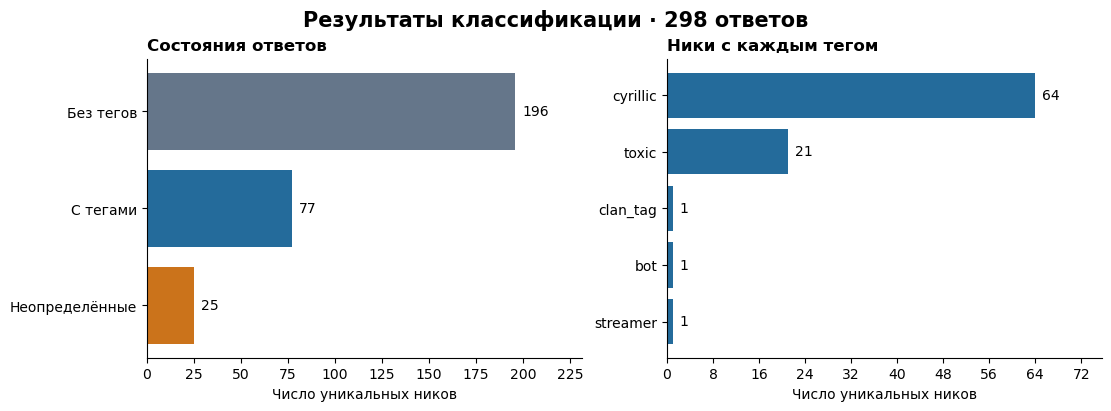

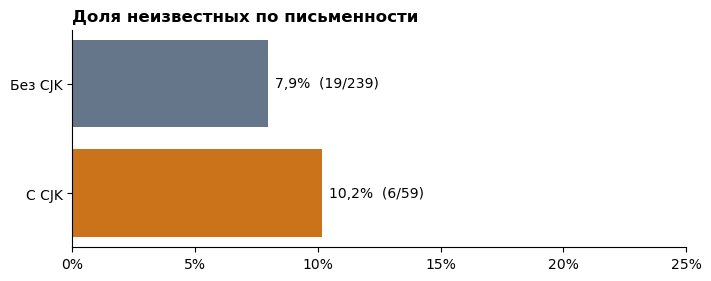

state,tagged,other,unknown,Всего
Письменность,,,,
Без CJK,70,150,19,239
С CJK,7,46,6,59


In [5]:
blue, slate, amber = "#246B9B", "#65768A", "#CB731B"
total = int(counts["Ответы"].sum())

fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
state_values = states.sum().reindex(["other", "tagged", "unknown"])
state_values.index = ["Без тегов", "С тегами", "Неопределённые"]
tag_values = tag_counts.sum().sort_values(ascending=False)

for ax, values, title, colors in [
    (axes[0], state_values, "Состояния ответов", [slate, blue, amber]),
    (axes[1], tag_values, "Ники с каждым тегом", [blue] * len(tag_values)),
]:
    bars = ax.barh(values.index, values, color=colors)
    ax.invert_yaxis()
    ax.bar_label(bars, labels=[str(int(v)) for v in values], padding=5)
    ax.set_title(title, loc="left")
    ax.set_xlabel("Число уникальных ников")
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    ax.margins(x=0.18)
fig.suptitle(f"Результаты классификации · {total} ответов", fontsize=15, fontweight="bold")
plt.show()

cjk_totals = cjk.sum(axis=1)
rates = (100 * cjk["unknown"] / cjk_totals.replace(0, np.nan)).dropna()
if not rates.empty:
    fig, ax = plt.subplots(figsize=(7, 2.7), layout="constrained")
    bars = ax.barh(rates.index, rates, color=[slate if label == "Без CJK" else amber for label in rates.index])
    ax.invert_yaxis()
    ax.bar_label(bars, labels=[
        f"{rate:.1f}%  ({cjk.loc[label, 'unknown']}/{cjk_totals[label]})".replace(".", ",")
        for label, rate in rates.items()
    ], padding=5)
    ax.set_xlim(0, max(25, rates.max() * 1.42))
    ax.set_title("Доля неизвестных по письменности", loc="left")
    ax.xaxis.set_major_formatter(PercentFormatter(100, decimals=0))
    plt.show()

display(cjk.assign(Всего=cjk_totals))

## 4. Примеры ответов

При включённом чтении MART здесь видны ники, теги, уверенность и признак ручной проверки. Для отчёта берём до четырёх примеров из каждого состояния.

In [6]:
if answers is None:
    print("Для примеров запустите ноутбук в JupyterHub с доступом к Lakehouse.")
else:
    columns = ["Пакет", "normalized_nickname", "tags", "state", "aggression",
               "confidence", "needs_review", "has_cjk"]
    display(valid_answers.sort_values(["state", "nickname_key"])
            .groupby("state", sort=False).head(4)[columns].reset_index(drop=True))

,Пакет,normalized_nickname,tags,state,aggression,confidence,needs_review,has_cjk
0,100 строк,aloha,,other,no,0.95,no,False
1,100 строк,天生我菜有b用,,other,no,0.80,no,True
2,100 строк,将軍,,other,no,0.95,no,True
3,100 строк,我就蹭一蹭,,other,no,0.85,no,True
4,100 строк,доктор глубокослав,cyrillic,tagged,no,0.98,no,False
5,100 строк,саня шуруповерт,cyrillic,tagged,no,0.98,no,False
6,100 строк,aliен,cyrillic,tagged,no,0.88,no,False
7,100 строк,виктор принтер,cyrillic,tagged,no,0.98,no,False
8,100 строк,ysun,,unknown,uncertain,0.45,yes,False
9,100 строк,squee,,unknown,uncertain,0.50,yes,False


### Зафиксированные наблюдения пилота

В сохранённых результатах **76 из 300 ников** получили хотя бы один тег, **189** получили other и **35** получили unknown. Модель отметила **47 ответов** для ручной проверки. Чаще всего назначалась кириллица, **63 ника**. На одной строке могли стоять несколько тегов.

Среди ников с CJK модель вернула unknown в **9 из 59 случаев (15,3%)**, а среди остальных — в **26 из 241 (10,8%)**. Это описательное сравнение по сохранённой сводке двух запусков.

## 5. Независимая ручная разметка

Размечается только текст. Используйте несколько тегов через `|`. Для спорных случаев согласуйте решение со вторым разметчиком. Встроенные метки можно проверить по текстам UNIQUE. Используйте следующие определения.

| Поле | Правило |
|---|---|
| `clan_tag` | Явный структурированный клановый или командный префикс. |
| `streamer` | Явный маркер канала или стриминговой площадки. |
| `bot` | Явный технический шаблон имени, например `bot_12345`. |
| `toxic` | Оскорбление, угроза, уничижительное обращение или явная обсценная лексика. |
| `cyrillic` | Есть хотя бы одна кириллическая буква. |
| `gold_state` | `tagged` при наличии тегов, `other` для понятного ника без тегов, `unknown` для неясного ника без установленных тегов. |
| `gold_aggression` | `yes` при явном оскорблении, угрозе или нападении в тексте, `no` при отсутствии явно агрессивной лексики в понятном тексте, `uncertain` при сомнении. Для `yes` укажите также `toxic`. |

Встроенная разметка содержит только ключ и три поля оценки. Ручной статус `unknown` учитывается в покрытии и исключается из расчёта F1.

In [7]:
# Черновик на 300 ников по тексту без просмотра ответов MART.
# 10 исходных меток сохранены. Остальные стоит проверить перед защитой.
MANUAL_LABELS = """nickname_key,gold_tags,gold_state,gold_aggression
ffda7b00facf899eb53ca4ffaa5140beaceac4cbfbf48ad8576fb8a26a5ee892,,other,no
f6804460f509a765b8ad07dca8c787ec984109088953153b8540cc1bb8a1c432,,other,no
fff126e306a3552b9597330080a51f86ec147f476c93365c96f28d36e0e0d526,,other,no
ffef70aa4cb048836242c85bf1c7e21993dc6099fad305a410754c15c47e9e90,,other,no
ffe38827de3c4c1d94ec49ce575f3ef207d3a205987f194d7ef0fdb9866dd03a,,other,no
ffef08c348e57283b7ec0de7b31614841d60255ad21998bcd8c2a053a8bcd022,,other,no
ffdcd4d62d6ad47fac76043c961cf2a7288a043ea34e517871d004862df290c0,,other,no
d099cab1cf2d8b34c7a304214f3bb6507575bd2710d9b8741bdfe5e060ad6728,cyrillic,tagged,no
ffdd84d84f2665573da6562d0878ce78d635fe59f7ca37e8e9cd5497aa4eef4e,,other,no
e10439b79b88b7c48ab144a70da726f90e6a08e79f4888ce042f67f678c67160,,other,no
ffe93a391db0021acc7e87ffab98b963926b5d5fc37695e7441b168048255793,,other,no
fff0f868f2a7161e5d4f202922b47c373be5ae0e9b94e62c36b06ad5d59c72b4,,other,no
ffe8dc3e917c1397c8fed7a051f0f69448ac28e7ee73fa7e44adfe48d13e99dd,,other,no
1913369449e2d03b5575e3c5bc1720055d9ed53eef1e1f8d843bfe90c9598114,,other,no
ffdeb3a49fc45475ddd6dd8df81949a5550782a8178d2e06babfb5dfe2d69f87,,other,no
78644cc1796e6dbf1b99746b0ee25ac216d83bb4ef1f1535b914ee7ba972eab7,,other,no
c2a97f9228885f03a1f8e0bb6a0f6c8b0daa5888356d6d83ef8c037387a0c40f,,other,no
ffdf51198d87db49175576da38a1a668f40c342a132a1526893065f05ca87f99,,other,no
ffde44996204280e35e69dbb96e135a6570171dde5e60701df858a22989757ae,,other,no
fff7c66041b1bf75bafb5748fc8dd1ef10a64537587d5c6cb6de03a5a4494261,toxic|cyrillic,tagged,no
c8deba6cb8e2305355e1af9a667823dcfce48f144bacfa58cdd813bb5db51542,,other,no
fffc563b0002130a9502f9e89eceae8558291e4100dd95cdf5e86c37d2214ae2,,other,no
ffef76a381537a5961d1b7cb568ab9bac5200d85c49d3e2f9a35ddf190fa28a5,,other,no
fff351c788de2cfd1ce917bb091c5c04562e4164a0dd600f9c08851074541178,,unknown,uncertain
ffdcfb0082eb3bf7c73a72e2d91ba974d87fe93579b17fd832422c12437ca448,,other,no
ffec95847fd4d60ac1b9a7b143440704f988524608f57a9d777faf8feb44c48d,,other,no
ffe0d10c0e5014ecc75b34d8386a8df25c265d0945810d0ba5cfe2558faefb53,,other,no
c6b5f36ea2b887c5138f526636279d220e4c46db3fd913fb81ac3b802dc04335,,other,no
bc30891fd8db776faf2e6ccff945cbcf92e7db9a8ddc89c0b5db1617ac282416,cyrillic,tagged,no
ffdfdcc096ddcde0f9250daf8b30f5b0a12a26c3d4aa3f847843d768f5c0f8b4,,other,no
fff8e6326fb9324a6a6cd4711b24db9c94862f759c15947f5bdcc684f973ab0c,,other,no
fff18f1ab8e49f469453b639ed9939186accd80f73a6b82d47d056af7615b53f,,other,no
ffe7d13fc66d75d6a47018f3c7fca501a50f76763a962f13aaccd818c0e00347,,other,no
ffdb913c35a0fed8ae5582472108e3907a7415c0ae405f4a12fd9c8186e2533d,,other,no
fff29a4f16c4b7818b02e76b1881da50e49f7e7f8e95038f75636b921d08bb04,cyrillic,tagged,uncertain
9c5604d637fc5fee7baf687592c9b29339dc5563d86a913d68f11ee7bcfe27c5,cyrillic,tagged,no
f6b15a1a77698067f61c1e1cd8b89b1cb0aba8fd787ff61fa5bb65785d7b7147,,other,no
6b0112289ccc20be9c2bcd5a84f48e805d27009d868e2e230bdfe1b179a6e5f6,cyrillic,tagged,no
ffefe686c3dd9a5857f7f531791bb34ee1f050257a992a344de7f4a82a4ce14b,,other,no
fffac6d435e4dee5d50e1c13c3684054a56a8f5b68796d26a7c62d631e3a5c4a,,other,no
14fcc7347e2989a30a21b474534c1e1b2039fa34e6e1f5ad667e5b855707a1dd,cyrillic,tagged,no
ffe6d2b769b9000fe919e59338db925ffdc40a44b6c379e8d60c918f4c4aded3,,other,no
ffff7a39c3a6f811748bf069830f82596625e9862dcb43afb5d544772cb07810,,other,no
7d249e86eb7fd93dec3c8bcf7a50e6cf4c6e83e427533eaeb4db556547e492bb,,other,no
fff1c68a566c44554fedb0b457667d2a8494d98fea9e10316791eabf39dec5eb,,other,no
fffe603ce06d741aa3704a4be58ec8e386b52c67d47b8ad392f6d37f8b77ca48,,other,no
ffe38d82b9def77b7a55cd98f39cece568456af7323466b7772c8dc82613229c,,other,no
fff2e6ba7639089494323b3ed95712658bbab95e525e7fa8c55ba326781367f2,cyrillic,tagged,no
ffd9baa6245c0db635b6b3950cc7575bdbd191f005641e1950d7f0be79f55b26,,other,no
ffdbc1c45ab877603d293f73ba6cfba00750abec0e77965410d96e7f14a33546,,other,no
fffca95a17a24a0ba7bce993814041533f2e2f626ada11abf946e81ff3f282ad,,other,no
ffe75473ec4f9632c1634f26587b7930f79a9fad03e4bb9d3f920dc5bda0ec3b,,other,no
ffe6d04688cd066672dca50610970150dbacdc0b7e24d14405d77842f9a4b205,toxic,tagged,yes
ffffe41164926c1543e967b52007a3150389e925ba1eb2ee1ae66aa325047f62,,other,no
27a4c0e28256266d5008d5f427f86ecef80c22a7c033562974b8333471c8f8c3,cyrillic,tagged,no
ffdd61412f0f922808edea2ab04ccf62173615c2976a6ce830c833d14375cd94,,other,no
ffdc935efe42125a6e1ac312c75b17ad8935677048cb9e17ada4b9aae9fbd8af,,other,no
ffda972455eff257338c2bc8d3fc20de221d29c489083637e7574066f703f5ec,,other,no
ffddc22cc8e932d9f69992b263e29dc4d5b426ddd6386f11b8c855c659218c33,,other,no
ffda50a0038e351702edc5d8fc6ac79ae6844443ae5dbe8edfc12a1c641b03af,,other,no
fffb57fd2f2034a635ade30a4f2a2a4ad245bf8d1eba8104b2275eb872fad020,,unknown,uncertain
0f50a317333f1a51c2b8869e543f57b2c49859e7c0eda8b9b77e0ad68c39ed1b,cyrillic,tagged,no
0aa2d72102aacd672ff0a86ce9f88361af509a11ad8fec65734d997ececea2a4,,unknown,uncertain
7cd668b9f5863aaa0b89056b579664bcec34499d289aac6c2618d8a1be3fb1b5,,other,no
fff10cc4a49bc8fa46db52c8b048946518d7bbea3eba384eb847b6cf0b339bfa,,other,no
ffeaf6568a1f4ec0c18bbaa6e1c20e93981f77269345132180f00d9bb5f94ea6,,other,no
3372eefe622f140d5da95fc9cae9d3b5e8d8c24dd5128fe9d5cd681a2068595c,,other,no
ffe443b5a5115b9b2afc0f452507fa03101f8307312d6443ac0b0e5f46b5e34c,cyrillic,tagged,no
b8d523825068230a86358286d4fa636dee57e20c26b3894eef6c62a83acd04c8,,other,no
fff07bfbf58e60949b0da6dadd4feab0bada166ad3ee48bb5661765ed0433fa4,,other,no
197905a6fbf90fd8b30dc0683cf6d08aaedcae21094d26c7ab50b4c86ccc3b29,,other,no
fff3c98df5efcf11739c078784d3f4a712ceffb6ebf77f2ec106696e20ff75f3,,other,no
ffe67adf723835c72d0bacf50161f37e671c2a1253b0bf51b8a34df0c718d030,,other,no
ffe79bda7697694765031a9cdee65b408e210e0374ce6266e07d77baf35a3631,,other,no
8e901a43b81aff8ce4debad8f19a334aaabb4a941318f435200b242cf9a3e088,,other,no
ffee69703dbc6abb441ed96c3c2aac070245eef6d43302b7f7a49f808a8754ce,,other,no
cadd82359c4b7c0adc45ad2b69da86fd2b42a58471458a39ee8d19f1a9385b24,,other,no
fff18f30f92bc6bf3ea7325f8e1a8b6978a72e256d9e6eb711ed49d032c1b834,cyrillic,tagged,no
fff9053213cc7140be39050b648e3f18e8aa0cab1a33c4ef0a9d40c2710d4d3f,,other,no
ffe5bd43951f0caf19c6db8438db764bb5dbd222715eaaf0b09e39205a422033,,other,no
9a7fc7b6b7acd8af82702c3d8a7bf7d5469c68477fb9398a9d20de880e3b8fdf,cyrillic,tagged,no
970c65caabce48337c115cdb7d5f9d702313daf109cba150be52832f1e363b56,,other,no
ffdce9fa7b13b43f31844e3aed9e4ea4bd2e46c7494faefd9b462773432e1d53,,other,no
dd6643e9f01560d100a93e6b87af69804798d85c03651d7278396cd7961c22c7,,other,no
7d4c5786fd9851641271cfde504d33019bff15c7ebb78220fff3c6669a92f4ac,,other,no
ffdb88029971ee07b27b29c3dfdbc2fd31bf28c990f0a5e10b94454e645ea725,,other,no
fff3c10efd9fd8dfcb09174d86930026a9b225fa42f6d494a9cd7e3857595765,,other,no
ffe17d800da31b19aadf626c28ab115f9e0f69abf0147eacc2c1539fb207e494,,other,no
ffddc44580e06123c7774531a67f945afdcd3fc8cc9ad74b8ce26351915c4941,,unknown,uncertain
ffd9cfbd0c5955e6af84d06f158c9a829b38679fb74fb3c60ac5cc57c17fa0af,,other,no
fff99489209bbbd0701f17b540ac4c50fa5a87957c7898a67d5241902455878e,cyrillic,tagged,no
18d82f06e3700e73c5f0596f379b08d9edcb857180de86c4fa5fcc61f6dd2e6b,,other,no
ffe65f578b517c23ebc13b4fac21a8e7b71392089fcc55c8fd153f94455914cb,,other,no
f4075eb670a989b3cff3c61089db248456ee9a24192c503778190bf68ef326e4,,other,no
bd658bddb6d121a6a34428d9b8e23600527746e361bc3c9a921acb16bb744755,,other,no
fff341da9c5218c38ccc3867615f61a9998483befb7f1439241e1880025faa00,cyrillic,tagged,no
fa0d34a40ca85f135b7c10b2ddfd78f97dfddc773e5ac39ada5c28c946403284,,other,no
fff108a070ab865691b3bb7ff1b26b268153a581d297e06135711bd8cab6d34e,cyrillic,tagged,no
c46d600336032138f3063b19d3893be83da72e870157814e8135a43e43e4e680,,other,no
8f30e8a2109bdede60143592fba3ac271195ad267bd6ff018aa3d0f08f994d3b,,other,no
ffe2d77f8f34dd3e382569c525bb854853e2b42a98fb47927d9a7b7a881f0b04,,other,no
fffcd48c0f8932df565a50c21fe6826cdb96728deb536897b6555ac96147805a,,other,no
fff22cfcf2f1bf5bfd38c741fceed9f8942d90d390b83ae0c732f3718807ce48,cyrillic,tagged,no
ffe87235f697864a2e67b3f13385762a13b37a6c44aa0ff1f0f7eb9d6f88b2ca,cyrillic,tagged,no
ffe0c0a986791b256feccd91dc4e7589df191057289744bb09906dc2146b53d3,,other,no
e4ab82099f39814a9277f0991ec860dea1bfaea343d5667941051a82e53f115a,cyrillic,tagged,no
ffd87e1da36c7fc1a7b233950bee116dc6993e9b6c7f47437785c5c4470cc0b3,,other,no
fffb44e4b08460009af6a13bf2732ad2ec65d13b69b298b8e67a932574569e4b,,other,no
fff342ceb5d91b878fad236789d4234380a6a189048d1e29b83ce34e7df234c4,cyrillic,tagged,no
ffe2a1be70d7c032da1623b2ea68827ce7f8944c5b0e76cc0881ab436f231c07,,other,no
fffb433d338feb6e2aa92154c4cdb94f00637bb82142bd7f621d0bbdfa6bf289,,other,no
febd42775730f447ffeba08341e2369c0d312c81ff7dc1ce74eeab66bfc197ea,,other,no
1dcfe36b97035f85392ec5c0a9cd2bb1112d4578363792e7b1e5fe433f919854,cyrillic,tagged,no
d27a1c8f610f33aa7e85bc1b106a151428fe8e8f6fa80ca60831315c00279088,cyrillic,tagged,no
9155d9810cfe0bc50aa44e0c2cad79fc936e71ddfb9bde368e6d38b46cf9d26b,,other,no
ffdf052dbb7555bbf676a175cc85e841a0eefb2e2258a8b1ccc2260c546ab235,,other,no
ffe150f4821179b8b7b9bb0ac190f4a9b96f41ab5409d7694120abd98a5bf50a,,other,no
fff1a77ec17cb8a955726a8f5a18ecfec643671a9c70de97cbec9c24e41d9099,cyrillic,tagged,no
ffebf91de904ea7b8b5a827143ea1b0ac5e1963893a7a1640f546762b7cb290a,,other,no
ffe5a8190ba21a6188419d10adbb4ac8299a9ca6b4e75b714f02381a8d34ad4a,cyrillic,tagged,no
03e73f4e36abc3c3ac8ac43494a0d1187aa820eddd39204f5844cb93e7226655,,other,no
ffdc513ad611650d2577b5736daa9fb199fce52de65a47824e7258a653f53d02,,other,no
ffea7e7b86106bfae1f10b328a42b29182d9479ae1eeeeaf3004e3f9b841da9f,,other,no
ffda7a5285dc4d3996a6d886c2be7c7da3a241606042e7140e2dd8c179c47b3f,,other,no
2c1f887ee2c458f51990693a0695ede0d6ec48423e022a79dc5e4728940c3636,,other,no
f8942678c28cabd9bf52fe7c3c4d79ba5c5b39ae8c064854b5325f7935896fa7,,other,no
fff243d048a1baba37ebe49a572401fe93a0e88e28afab1a615820bd8448e1e1,,other,no
fff80ab26b1df2aaa17f6db01c7c33c2e8b4eacf131620303ec971db155c0dc0,,other,no
ffe02f5c9d561ec2f472510cd73af7d1c7c411a37a202fea695126af3245160a,cyrillic,tagged,no
fff2eee4c15b7a2a0011a881a8557d417faa85978d0b2d38808d9c76d5e16736,,other,no
ffdcff29230b8e11c4e85b959e3c51fd03074a4e0b2c4fbb770ff9aee136e2f4,,other,no
35d182bf76f60cae8da1d3f208be2b9c87e0824785235bea821b807af215ec0d,,other,no
ffdb5eb0ca272b1e7faefaaad702131c79fabac0c150700e67460f4d06506cfa,,other,no
fff0d5e9440831dcd7db11237622060fd1673ec08eb7ef9bf6d854894e41c48c,cyrillic,tagged,uncertain
fffd9f1a70378d4d382a6130be0c1047e6c46cae8f2e21acac1c4d3497d24c06,cyrillic,tagged,no
ffdc7da9910b330a8d43b8e9a8698e0f6de29ea03d184595953ddd67f36a793a,,other,no
fffe9783f35c00eaf69187ef5a05d72f2905bd503f99a80883275335d5507f7b,,unknown,uncertain
1a48244077e5b210c2cff26df622bf7e6124c6156486ed5c321690370856387d,cyrillic,tagged,no
49120265b5f0d1be90aade35dd3d0b92fef2c60d512d01d6fe9882ad93bb1266,,other,no
ffdc6d0df58b3d8f229461307080a42ac6b4fdef14768eba0fefa71afaf1e5d3,,other,no
281b3cfdb7dc5edc9792e66cb78c8fec160f61140cf452875e34b355ad9ddd96,,other,no
ffde6a9fafa54bfabd4d1188dfa3a25b003b169be5e64fbb80eeae4fc9535091,cyrillic,tagged,no
fff5b9fe8e419e0b8e24084a69a74abd87d2c2b5850d97abee45bdbecaae6428,,other,no
ff1e83a11ac391233ed225996c3bc8caccec1031cc1c7ed4d2a421e8391d7235,,unknown,uncertain
ffe5afc5549f5ee36c09916f862e10702af15f0e88ccc0b7f0dfa007e3f62d9a,,other,no
fff2effeeb712864e5bd1b50553b04ec1b5b8539b5ea126059cd978d86096804,,other,no
fff1aab3452243f96e8efd6824aa98014b77721b0841f957b9efc04877012024,,unknown,uncertain
ffe9efa5cac00ba52ace6e22def9bebb2fda694b2bad07b42b1cb51dc5396a4e,,other,no
dafb2d443b231796bcffa967089bb0fa1fbb021e0ef1ee566747ac9297f7abf7,,other,no
fffa241694e26cb2d29d863635e08ae662ec2970e3ca884eaa24975b7e923e24,cyrillic,tagged,no
ffe11d077386985cb3a150750ac379ec4a1aab1cf4131ddce777d0b7f4c5c4eb,toxic,tagged,uncertain
ffe9d54550f6d6e81c6813a9c39889d7d2ca7d2262035d3a7e70016e2d92c377,,other,no
ffdcfa049ca9e74ffdcdf4176a658b7aeead4ef50c364256a9402b45795df189,cyrillic,tagged,uncertain
fff4a72ac6861f37cad96321f94981d8aed3bf9c44b51e62b486b581e0bc658c,,other,no
fffd7472d89b9f7b14b49879c734575d1a1ae27fe56e3e97cdf912cdf2ef6444,,other,no
090e367f47518d51d377fd6b7d07b3d5063d00bbd6b3eb42ae8265e99c145cd2,,other,no
fff9de1de1c34c68c4df4fe40c7bfc6182ab22a748dae13356b46d994c315bee,cyrillic,tagged,no
ffefdc58c7c56897db5eb292128eefda00c2e42490f1cd1de0868c56dd883d81,,other,no
ed11304ec654c22e79bda83ed516157803a11a0e03544512a00649ae9d221c90,,other,no
ffe447e325528b6f4c446f2d8d4e2030f5ca0ca660bf35a4749f8c036bd042ee,cyrillic,tagged,no
fff0d31e95d65c621f6437847d4733786721fd2bd4b254f100d19a28a8bddb1c,,other,no
ffe7500dbe4e4c2b2446bd4d510317fff8092d1d8df8aa91eb79441ec6fa9c5e,,other,no
fff5374a517c69696fcd3e05d2efd86b5c55502cac088d2b8476b7dd33bca4da,,other,no
e6ad2f5fcd984acef62fbc6014a7b76fbe6f482971abefc19c5ced24311fc29f,,unknown,uncertain
fff57e12576d1c78e9f6d14eade98d0c07a0607807717c28180db659af34c90d,,other,no
9089b0edd3687d3d1a100505d26601faae83843c5c4c62c1ff4633d3759e3918,,other,no
fff58605b81bd2918f0c115a2c2e01a4cdedf65da3227e3aae4abdff8516712b,toxic|cyrillic,tagged,yes
ffdd16b46ca5350a917a9aaf8415214344e3e802f3c67617e9653c6b65f01ed0,,other,no
eecdd0100850f51ae82ec2745e136bdf152f275f0a2edc1ad3f1bc5f9b61d0c4,,other,no
ffef54de7b04a47fc36b4588218955c4bdc6e268c036093dede83b782d43c154,,other,no
fff520aa0a741d0006caba1bc00c97f9db2678ae62a59d54497a9f78f1bf5e6b,,other,no
fff38abfdeeb58f03679c24063b726d88f1d32aaa978e6b7f668db27826337ce,,other,no
fff67a128444f712b17456473fb08d22b00fc971ee81e9ffdc7f5c240b95dab7,,other,no
4950768755ce2dc2594c1d2496e23107abea65a72df9e7940a1c01f4dec7bfc4,toxic|cyrillic,tagged,uncertain
fff0eb9515afc926dffc4668168cbd7b8441d3f0478854f35a17e9328473236f,,other,no
b01bc92f3c31cb767720e092bf6a361b9c9572acbdd70283dc8b9cbcffdbb91b,,other,no
ffe86495caac916c6d64476ffa64b6ebd52ec571e83312dd2262b135096ab7b4,,other,no
ffe79b63fcb48586b10fa3fcfc9e7375fc52412ee70c1f14077afe3aea9a9416,,other,no
ffeffe4eb65c41304d0f7793b4aa81d3de8600afaa7b737c4bd36ef4c97cce1e,,other,no
fff9ef50394099e3d9e5cb522f8b2c5bbed3ee2f9151004d54ebe0099f146818,cyrillic,tagged,no
ffeed1137464f5086ee280877063e16b1f18b6f7669dbbd21292b34bee0008b9,,other,no
ffdd55d824ef94386c5095078388780d0c6ca688553de02d13377b3a8f0b81a5,,other,no
fff5b91474062d0b2bd3a4ca77f298f8613a32f2862b6efd98aa6c4647c57e32,,other,no
ffeddd37254491d9b884e279c25e7e4b7c9963e6a2e5e022e477dcfbc1671bd1,,other,no
fffa08b59e0c2cbafcef8decfa342552f456847dfee7313b82cb4179c673f65c,cyrillic,tagged,uncertain
ffda893fd75b1893bb136f1f7f4c4f9626b67ffa91199047698b3dfb4ac22a18,,other,no
fffbf4c389e9ee5208693d8003ac57830b9fe0b79fafd77e15ba9f0dd22eed38,,other,no
fff11551e37cf37e0b563dcfea396930a66a4ca47ccb7fbd81f5a81d68b16548,cyrillic,tagged,no
12f980a28c8813fca59d783f35677ec7441760abdc6d526fdfeb38bdbda4e81a,cyrillic,tagged,no
ffd8e3ec31d4bd28c3d8748b3ebfcee824bbd97493e2ffb0c08fc8fef2092281,,other,no
ffdfb41684be6f069af94521f8f488c97205b6d7c69c388d43e5ed0fb1915ae3,,other,no
fff4db8d4cc48cde2ace6215eb44163767265d29c42b247e3bd506afc210baf1,,other,no
0e4b4a18ff1e69ec5f81635f1f3f1af20390c337684f4ef51da1bab3ea8ef096,cyrillic,tagged,no
ffdd9f593a7846eeb7059d2606439c0510385efb35cc67257eca9d60069abedc,,other,no
fff19a682ea8b665411196f08937e2a0ccd27d69c22a981e01f20cff87249d14,,other,no
ffdb275acd5fad14ebf541cf2b51932eb6447e09e33b91da4bdcc54a1e6699a0,,other,no
ffe89b3273084b3c142489411a2075ed26461630683c758a74d533c4f2a09095,,other,no
fff8ea2eca5557b7c66a5ce5bde7f461af5d942dd404a45c2e6f4469c1f4d69e,cyrillic,tagged,no
fff4894a340fcd71cddd869a68fa209e4bc5d37d693cd92ac6298f125dfdea6e,,unknown,uncertain
ffde7d21de8e50d7ac83d763e499cc1b62fe661c4ae63e2168589b99287ce72f,,unknown,uncertain
fff63f9ef435676bbd3274320f96b3d91fcc8f8957859973aaaa21e9ab2cf94c,,unknown,uncertain
ffe5415ebc6299401fb5a6a76deb9a9c1ccae84a2d16d390349fe5e9ec2f824c,,other,no
f2aabda8d5c5e99e8d39becf0a0cd7e07f517cec3ff5557df32a41e61e9c10ad,toxic|cyrillic,tagged,no
ffd95d5deb11833c8247d0a459da3b83ccebab300db65c3f2464db3ad454947c,,other,no
ffe52043dff7c8791522495654f91b8235dfe883eb1ab2bda3661d2ca1cd7077,,other,no
fff48c4823a6ddced8e1277fc0a98f7b11e0caaa4cab89e2bc3659798723e39f,,other,no
e454f5b950049a1b1288039b3c4262ee1938b5152ac645f938776e22ae3f09b5,,other,no
8e58cff4e3e21268c1c45c52b5b7bea825013a09fc066a9dca919875a73e9b4e,streamer,tagged,no
fff5dc2c14b302e9ce667d43c7a7fa499a80e515124a7c176b93d52538f1368c,,other,no
f5c94f4905e1ab6af073f58e7698016d5a8815136700337ef3d23b19ad0f4c29,,other,no
0a73d6e4fa582430c1af47f1cb127b1b81e9857daedb1fe526ca002e5a11c0f2,cyrillic,tagged,no
fff673f29bede35aa7821455f175b56beea24d5d6b95a1aa2aa6a34d28fcefa8,,other,no
7637dfbd4a24ae47845e395ea9684a102e3eea1ed628f52d1955fc8486e8487c,,other,no
338a9b17d1edb7fc838b49c6e3b43673338bc72827d067c21e30bd85b2a7a608,,other,no
ffd9bfe6029cbde32b6b63967de4c6beaee6a4bc9d19476ac468a04aedc8a0ee,cyrillic,tagged,no
2a9d04c60c04060dae279ba25271f00fa8a01ad51d81347004ff6594baed99ab,cyrillic,tagged,no
fff7bcf4466312178c0237d7fc21eeef89d431814f53c592b008015c2a44321a,,other,no
ffe8846390b632056193e60f2a8d769921d8cc9adb4dfa890f401eb44a04becc,,other,no
ffffa0d75424b0936ae8219bfa9ed6facf083300d04080cd60b15183706f11b9,,other,no
fff007cd0cbe943c3a11e2f3abe53b82fa748d3d2db12172d6c30b6bdcad566b,,other,no
fffb2866a020ecc85cd119da4c5dd2ad80b78f96dfc40cc4bedc8933713ce905,,other,no
fff694e793abf400892ce7bc9c44f5cc7a7e8b8039ed2613f707a25cfad0acaa,,other,no
ffe6888e4657dfa05a2e8dbcf05a7792949d46a8b49c5f0862c9644af63b430b,cyrillic,tagged,no
5a1b52ac215a943732adc82948f75cab5722119519125efb0669673bb1f4d7bc,toxic,tagged,yes
2fa49ab4537eff379394025655e0ac9ebec837e08ec7d03e5c1745d7e77fd788,,other,no
74ec9cc9e324aceda4060884128efe8c4fb4e6c8e6651f3286e4db65353da875,,other,no
0206a97843b1ba4fbb147d472550ec3b5ee8aacadf3707522157240940d1bebd,,other,no
161c9d0bff0168595633df96011346be65bdf8e35e5d20e3f34e6d440f85f7fa,,other,no
ffd86fe07d57221aad9d9d416dbbb385a2f9b428ad6f55d76f617e8fe0b24ec5,,other,no
a2eb1d4585d572d561f01200bc17789197d05aecbd38a4fde9781b2158ae5315,toxic,tagged,yes
ffe5078f5ea74ad1db6b82620761f369ebdaa2cf67419f0a22303431555fbfb4,,other,no
ffea5cd701140989c89718a7052bef0116f959c022e9eec62823e2a6244959d9,cyrillic,tagged,no
fff4b270f22f59b197df96ba8f14054cb70e70d1c313c6d1df3934525a6f96fc,,other,no
ffde254b0057c9d540590add0cb099173ffda48c36a3dead968abade52d50d4d,,other,no
fff3e90e492f9b751855d1b8166013a57d438c7c3157d33960bf2b4ee9714cfb,,other,no
ffe14465afbb51efb21e88da607dae2baf08c56db9092b47a5385a33185b3935,,other,no
c195bc8dc199071f70278026f76c3ac26c1d057c1b6e207896e9c0ffc2d53a79,,other,no
fff6390095e0b3f231259ac0c76104527610dcfb23a56ebb3ee2dce386a00409,cyrillic,tagged,no
fff1e3d373647f0a0f46a5deafa7e2c7d02c0f6df223f79d1d14d6bbd6370ed7,,unknown,uncertain
fffc4b7e5d7a4d8f2f0c7cd2fdd1e39ac254bf61345d558952f9596dce127dbb,cyrillic,tagged,no
fff583baed4219ce8c7553969ee78b3e5a79c7c2535c7b12c95f98197517b2eb,cyrillic,tagged,no
ffe6b2d24d7bdfcc7ab02ced6d505b87f5b27c97f21c88b21aa97af8d5b8c8b0,,other,no
c43f204a4970c19b49667047c0bdf5891c8a7bf24dce6c1d7be085721f18d2c5,cyrillic,tagged,uncertain
ffef158e6650f28768b692ef7a1755dd4ab61f38ba22e7b678249ac0d82e0cc6,,other,no
779053b1404e16dc6e24a2b12e58cce45f9553992ba9875601d76bc819312b48,,other,no
fff3d9756632d5f25e969b35055e2933e14c226ca8a68494b8547fd4e8cd8b7e,,other,no
b366b63cdf5e6166316c21fa9b38b8f82634708576fadc66f95d91d69198ceda,,other,no
33215f3e25d41bf49b959ca66eae2218f0e2b6c35beb50376381fa72a4ca6701,,other,no
ffe8d2db1a7a525d36a74702cb4416df4dd9d08099bfb1b28162985f796b4de5,cyrillic,tagged,no
fff09e55c04eb1936c754db5b355762bcf6ecf4283a8bc28f9f59da1532d8f45,cyrillic,tagged,no
fff027a3f7f68092790f5e60ebe74b491aa7f35b048ee79856578b2e9f8fc95b,,other,no
bd2654c254fa351a2be80e3c88d4c047e823ffb93c7d53d5d61c8a016ac9c74d,,other,no
c33edea907cd3da1f320fab548698fef77bb210d30562b0370df6c92d50d07d7,,other,no
d9e2e6ca0fe7e1b864bc5055bbe67febe7d00ddbe8765645b0b6e379bbb6a643,cyrillic,tagged,no
fff92307b0de290b16ce2b0e1b3df9312180701517eaecca2b4a66f424296266,cyrillic,tagged,no
d5a7fd302ee1f86dbe4820471fbb3fbf78702af4b27f66562e3a338a95d855f0,toxic|cyrillic,tagged,no
fff64d206bab0e49541e1035e7f1fdbb10353e6bc96affb4d75f301d218683c5,,other,no
ffdf4a94bdbda42a80e79efd8063f885abe935eab013d6b5ae0981dd5442066d,,other,no
fff5ef4543f69e461f8f83d0b489bc4cecfecdf75c8ca6c2ffb26971e5a97fae,cyrillic,tagged,no
4787d986d65953f5394cd7f80108b788c9203adce32fcc308d8d09b5213e8bfb,,other,no
fffd9bd7ead4ecc9c0f27316aa5ca61f6a9fb64d9216818174ae2e90331ea8e2,,other,no
017639fde70976bfdec586106d2ff9cc7b23dfed5f4ad84171438ee785113da9,,other,no
ffff6cf0cc886742128618ff5b9fc2af88800140c360cb4092dd0d11156da354,,other,no
ffe60e75e8ab9fb92e3066b63eeef390c13d13811c92a0cc0c6cea711096fcc1,,other,no
29ae82b2caf36b9d590f383903d1496b638ab8fdf1078dfea4830f49f29b0958,,other,no
972aaf0d14e03eb6e1aad25aa71bae664efa53f83ac6d21245de0c2d394f8162,toxic,tagged,yes
4a37b9dedc82bcb99709bd42019f6f73615f8f5deb5de9ae95ea31e33ef2b32a,,other,no
ffdcedff668f8bcf1bb925de0710d11fe1c2b83d88ca3d947ea6c8b70c1addd1,,other,no
fffd2a2d64db2489e8916e4580e576370f235f368f4077899a3220d2d76d09c6,toxic|cyrillic,tagged,yes
2f6b1bd4b971f7b32da039f8ed79dec2fbe2567787ef60b0458b4a8977e35527,cyrillic,tagged,no
ffdc1659091c5a0c550132d998db67178be4e5abb3aac46e523cd11443873502,,other,no
ffe9412425385d503aaead26e47675f7af3581925bc904e8e2684aba365dd3f3,toxic|cyrillic,tagged,uncertain
fff079e659a46eda2b7d8ddddda70b4c86a0ab44cdb0193daf75b4d85b92c4eb,,other,no
ffd90e23324a0f82dda22f8d6bbfcb62fec90550cce80514f4f848d93277fecd,,unknown,uncertain
fff0c1a50fea50d79fd3462bd38e297f0c790d095f1fdc188de127da6d75ee67,,other,no
1924bd4370a3b88d85ff5b75576f340d12191df8062ff98b8eae9a73b4e373ad,,other,no
ffe6cd51c7e97f3c10f57e3cc7d3c4c3c1e58712d40c6bab1899ead09e8eb6e0,,other,no
bc49b074112b1997a3d24e64c135230cd002f9cd60e79c2f7dcf22bb38f1eb93,,other,no
4e834c627e69f3afed885c6bd97623994bd08cad4f21bd6bde071e222a532f0a,cyrillic,tagged,no
fffe60acb8d0cb6068f73f67a7e8eb381f3f7e4e1274b7e255f820697c1c1d63,,unknown,uncertain
ffe9b65dc28703decc6477334825ebf578b969ff3c8141ca4c9e01b100adc45f,,other,no
98743561eb7950dc485072cfecdd134e0b0745e8407a612d34f40de006b949ce,,other,no
d5c347ac67d35b50e101b40af58c8bd4c712057a0999b08342a9dfe8083b6de7,cyrillic,tagged,no
7dc14eaeff455d08ea0f5d9657828fb75eafea0f9e3a0b576543692491b5f3b7,,other,no
2996bb950ef79dccea289269984bda56c33a93a5b319b3b65f5041f519ebf9dc,toxic|cyrillic,tagged,yes
fffd78ab2f1450d1790fde146af3d252732d71cf2d212896e0925dd52affa9d3,,other,no
ffea9491235b49663f034845e6452f82cbafd2314fe5268a2dc09edd04ee9a1a,,other,no
ffed3152e3dd4a41f8f6e1345ba608affb63725dc018fd429f7d127e9026ef1b,,other,no
ffebebbbf8a9f7fef10415de572ea8530fdde964370fd74e4bd02be4ebf0f4bb,,other,no
84449ed5a44a4e646507aa7c5c878a22e39cdde8c9255d658f9621a0d022e420,,other,no
17f17fa7a40e24452698ff279839657b7f636a1ec388f4098cc5fad2da7743d4,,other,no
0bb16246768cd6402c6536113c1a4407bc17453dc983d356a2d223b4aa90f2da,,other,no
ffe205890b733233fb7e5dae6f1d166cdfaa41434d1583361ab68e9c1df56492,,other,no
f200a51e4d214002648fdbaad3ca0635a457ab3d2e8b97306248569426e63992,,other,no
6d667b830e155f360a347b05d2138cc23a4c0fd032d84f7864eac5608e84c3b3,,other,no
fff333f66e419dff798940737c60d66fec93b6928398fcc28ef8ea2084f720ad,,other,no
382d211299c0e6e19d38b58c625d8174515e08c9edfea96d507492d2ece32ac3,,other,no
6de257ac9ee41db74e3c772376643b5080f7fd900a71000e1950fa92a2d8f8d1,cyrillic,tagged,no
fff21bf36cdcb57d95f6e6e714b60b1c2f991525debb79a0206786a3d228ac86,,other,no
e037319a860191385a7389a7170ed63967413c881bcfb9d12c81fc8d687373a2,,other,no
"""

def load_gold(raw, keys):
    missing = set(review_columns) - set(raw.columns)
    if missing:
        raise ValueError(f"В ручной разметке отсутствуют поля {sorted(missing)}")
    gold = raw[review_columns].apply(lambda column: column.str.strip())
    if gold["nickname_key"].duplicated().any() or not set(gold["nickname_key"]) <= keys:
        raise ValueError("Проверьте дубли и соответствие nickname_key текущим двум MART.")
    gold = gold.loc[gold["gold_state"].ne("")].copy()
    gold["gold_tags"] = gold["gold_tags"].map(
        lambda value: [tag.strip() for tag in value.split("|") if tag.strip()])
    tags_ok = gold["gold_tags"].map(lambda tags: len(set(tags)) == len(tags) and set(tags) <= set(TAGS))
    has_tags = gold["gold_tags"].map(bool)
    has_toxic = gold["gold_tags"].map(lambda tags: "toxic" in tags)
    valid = (tags_ok & gold["gold_state"].isin(STATES)
             & gold["gold_state"].eq("tagged").eq(has_tags)
             & gold["gold_aggression"].isin(["yes", "no", "uncertain"])
             & (~gold["gold_aggression"].eq("yes") | has_toxic)
             & (~gold["gold_state"].eq("unknown") | gold["gold_aggression"].eq("uncertain")))
    if not valid.all():
        examples = ", ".join(gold.loc[~valid, "nickname_key"].head(3))
        raise ValueError(f"Проверьте теги, статус и агрессию в разметке ключей {examples}")
    return gold


evaluation = None
review_complete = False
review_columns = ["nickname_key", "gold_tags", "gold_state", "gold_aggression"]
inline = pd.read_csv(StringIO(MANUAL_LABELS.strip()), dtype=str, keep_default_na=False)
gold = load_gold(inline, set(inline["nickname_key"]))
print(f"Встроенная черновая разметка: {len(gold)} ключей.")
if answers is not None:
    with_text = answers.loc[answers["normalized_nickname"].notna()]
    evaluation = with_text.merge(gold, on="nickname_key", validate="one_to_one")
    review_complete = len(evaluation) == len(answers) == len(gold)
    print(f"Связано с MART и текстом ника: {len(evaluation)} из {len(answers)}.")
    print(f"Ключей черновика без совпадения: {len(gold) - len(evaluation)}.")
    review_coverage = pd.crosstab(evaluation["Пакет"], evaluation["gold_state"])
    display(review_coverage.reindex(index=counts.index, columns=STATES, fill_value=0))

Встроенная черновая разметка: 300 ключей.
Связано с MART и текстом ника: 300 из 300.
Ключей черновика без совпадения: 0.


gold_state,tagged,other,unknown
Пакет,,,
100 строк,30,67,3
200 строк,40,149,11


## 6. H1 · F1 модели и правил

Для каждой метки точность и полнота рассчитываются по одним и тем же никам. F1 = 2TP/(2TP+FP+FN). Ручной `unknown` исключается. Для машинного `unknown` или ошибки формата используется пустой список тегов. Теги корректного ответа учитываются и при флаге ручной проверки. Теги без положительных примеров в эталоне не участвуют в решении по H1.

Основной критерий на выборке — положительный ΔF1 хотя бы по одному из пяти тегов. Для проверки устойчивости считаем парный bootstrap с повторным отбором ников внутри каждого из двух пакетов и поправкой Бонферрони на пять тегов. Нижняя граница выше нуля поддерживает преимущество. Для тегов с малой ручной поддержкой показываем только точечные оценки. Интервалы относятся к использованной выборке и способу отбора.

In [8]:
PATTERNS = {
    "clan_tag": r"^\[[\w-]{1,15}\]\s*[\w]",
    "streamer": r"(?:twitch\.tv|youtube\.com|youtu\.be|(?<!\w)(?:twitch|youtube|streamer|ttv)(?!\w)|(?:_tv|ttv)$)",
    "bot": r"^(?:bot|npc|ai)[ _-]?\d{2,}$",
    "toxic": r"(?<![^\W_])(?:идиот(?:ы|ка)?|дебил(?:ы)?|ублюд(?:ок|ки)|сука|мудак|idiot|moron|fuck|bitch)(?![^\W_])",
}
CYRILLIC = re.compile(r"[\u0400-\u052f\u1c80-\u1c8f\u2de0-\u2dff\ua640-\ua69f]")

def baseline(nickname):
    tags = [tag for tag, pattern in PATTERNS.items() if re.search(pattern, nickname)]
    if any(ch.isalpha() for ch in CYRILLIC.findall(nickname)):
        tags.append("cyrillic")
    return tags

def f1_from_counts(tp, fp, fn):
    denominator = 2 * tp + fp + fn
    return np.divide(2 * tp, denominator, out=np.zeros_like(denominator, dtype=float),
                     where=denominator > 0)

def compare_tags(frame):
    frame = frame.reset_index(drop=True)
    truth_tags = frame["gold_tags"]
    learned_tags = frame["llm_tags"]
    rules_tags = frame["baseline_tags"]
    rng = np.random.default_rng(SEED)
    draws = np.concatenate([
        rng.choice(positions, size=(BOOTSTRAP_REPEATS, len(positions)), replace=True)
        for positions in frame.groupby("Пакет", sort=False).indices.values()
    ], axis=1)
    rows = []
    bootstrap_deltas = {}
    for tag in TAGS:
        truth = truth_tags.map(lambda tags: tag in tags).to_numpy(dtype=bool)
        support = int(truth.sum())
        row = {"Тег": tag, "Размечено": len(truth), "Положительные": support}
        bootstrap = {}
        for label, predictions in [("Правила", rules_tags), ("LLM", learned_tags)]:
            pred = predictions.map(lambda tags: tag in tags).to_numpy(dtype=bool)
            tp, fp, fn = truth & pred, ~truth & pred, truth & ~pred
            t, p, n = int(tp.sum()), int(fp.sum()), int(fn.sum())
            row.update({
                f"Precision {label}": t / (t + p) if t + p else np.nan,
                f"Recall {label}": t / support if support else np.nan,
                f"F1 {label}": float(f1_from_counts(t, p, n)) if support else np.nan,
            })
            if support >= MIN_TAG_POSITIVES and len(truth) - support >= MIN_TAG_NEGATIVES:
                bootstrap[label] = f1_from_counts(tp[draws].sum(axis=1), fp[draws].sum(axis=1),
                                                   fn[draws].sum(axis=1))
        row["ΔF1"] = row["F1 LLM"] - row["F1 Правила"]
        low, high = np.nan, np.nan
        if bootstrap:
            bootstrap_deltas[tag] = bootstrap["LLM"] - bootstrap["Правила"]
            low, high = np.quantile(bootstrap_deltas[tag], [h1_tail, 1 - h1_tail])
        row.update({"ΔF1 · нижняя": low, "ΔF1 · верхняя": high})
        rows.append(row)
    return pd.DataFrame(rows).set_index("Тег"), bootstrap_deltas

h1 = None
h1_draws = {}
h1_note = "Для пересчёта F1 запустите ноутбук с доступом к MART."
if evaluation is not None:
    h1_input = evaluation.loc[evaluation["gold_state"].ne("unknown")].copy()
    if h1_input.empty:
        h1_note = "Пока нет ручных меток, пригодных для F1."
    else:
        h1_input["baseline_tags"] = h1_input["normalized_nickname"].map(baseline)
        use_model = h1_input["reply_valid"] & h1_input["state"].isin(["tagged", "other"])
        h1_input["llm_tags"] = [tags if use else [] for tags, use in zip(h1_input["tag_list"], use_model)]
        print(f"Ников для F1: {len(h1_input)}. У LLM {int((~use_model).sum())} отказов и ошибок формата.")
        h1, h1_draws = compare_tags(h1_input)
        display(h1.round(4))
        evaluated_tags = int(h1["ΔF1"].notna().sum())
        improved = int(h1["ΔF1"].gt(0).sum())
        supported = int(h1["ΔF1 · нижняя"].gt(0).sum())
        h1_note = f"У LLM выше F1 по {improved} из {len(TAGS)} тегов. Оценено тегов: {evaluated_tags}."
        if not review_complete:
            h1_note += " Разметка частичная, результат предварительный."
        elif improved >= h1_min_tags:
            h1_note += " Критерий H1 на выборке выполнен."
        elif improved + len(TAGS) - evaluated_tags < h1_min_tags:
            h1_note += " Критерий H1 на выборке не выполнен."
        else:
            h1_note += " Для решения по H1 нужны положительные примеры по оставшимся тегам."
        h1_note += f" Нижняя граница ΔF1 выше нуля по {supported} тегам."
if h1 is not None:
    h1_note += " Эталонная разметка черновая."
print(h1_note)

Ников для F1: 286. У LLM 25 отказов и ошибок формата.


,Размечено,Положительные,Precision Правила,Recall Правила,F1 Правила,Precision LLM,Recall LLM,F1 LLM,ΔF1,ΔF1 · нижняя,ΔF1 · верхняя
Тег,,,,,,,,,,,
clan_tag,286,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
streamer,286,1,1.0,1.0,1.0,1.0000,1.0000,1.0000,0.0000,NaN,NaN
bot,286,0,NaN,NaN,NaN,0.0000,NaN,NaN,NaN,NaN,NaN
toxic,286,13,NaN,0.0,0.0,0.7059,0.9231,0.8000,0.8000,0.5263,0.9655
cyrillic,286,64,1.0,1.0,1.0,0.9844,0.9844,0.9844,-0.0156,-0.0517,0.0000


У LLM выше F1 по 1 из 5 тегов. Оценено тегов: 3. Критерий H1 на выборке выполнен. Нижняя граница ΔF1 выше нуля по 1 тегам. Эталонная разметка черновая.


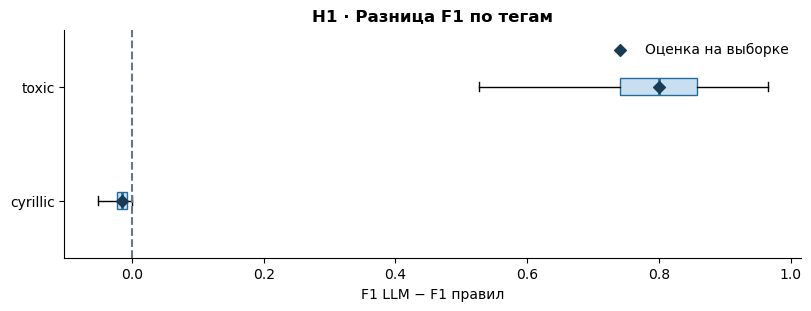

In [9]:
if h1_draws:
    tags = list(h1_draws)
    boxes = []
    for tag in tags:
        q1, median, q3 = np.quantile(h1_draws[tag], [.25, .50, .75])
        boxes.append(dict(label=tag, q1=q1, med=median, q3=q3,
                          whislo=h1.loc[tag, "ΔF1 · нижняя"], whishi=h1.loc[tag, "ΔF1 · верхняя"]))
    fig, ax = plt.subplots(figsize=(8, max(2.8, 1.8 + 0.6 * len(tags))), layout="constrained")
    ax.bxp(boxes, vert=False, showfliers=False, patch_artist=True,
           boxprops={"facecolor": "#C8DFEF", "edgecolor": blue},
           medianprops={"color": blue, "linewidth": 2})
    ax.scatter(h1.loc[tags, "ΔF1"], range(1, len(tags) + 1),
               marker="D", color="#183B56", zorder=3, label="Оценка на выборке")
    ax.axvline(0, linestyle="--", color=slate)
    ax.invert_yaxis()
    ax.set(xlabel="F1 LLM − F1 правил", title="H1 · Разница F1 по тегам")
    ax.legend(frameon=False)
    plt.show()
else:
    print("Boxplot H1 появится, когда есть данные для расчёта интервалов.")

## 7. H2 · Разница долей поражений

Агрессивная группа определяется ручной меткой `gold_aggression=yes`. Нейтральная группа требует `gold_aggression=no` и отсутствия `toxic`. Неясные и неразмеченные ники исключаются из сравнения. Текст привязывается к аккаунту по последнему доступному нику в CLEAN. Если ник менялся, его текст в момент матча может отличаться.

Единица анализа — игрок в матче. Разница стандартизируется по общим стратам «режим × лобби × сторона × ранг». Неизвестный ранг учитывается отдельно. Доверительный интервал учитывает зависимость по аккаунту и матчу. H2 получает поддержку, когда нижняя граница превышает заданный порог разницы. Результат описывает связь в доступных матчах.

Если после соединения мало подходящих матчей, таблицы покрытия покажут, на каком шаге теряются строки. Используются все матчи с 14 по 15 октября 2026 UTC. Проверенный снимок содержал матчи с 14 октября 12:44:45 до 15 октября 08:14:04 UTC. Расчёт берёт актуальные снимки и выводит их идентификаторы.

In [10]:
def latest_snapshot(spark, table):
    return spark.sql(f"SELECT snapshot_id FROM {table}.history "
                     "WHERE is_current_ancestor ORDER BY made_current_at DESC LIMIT 1").first()[0]

def pinned(spark, table, snapshot):
    return spark.sql(f"SELECT * FROM {table} VERSION AS OF {int(snapshot)}")

def build_outcomes(spark, groups):
    start = int(datetime.fromisoformat(WINDOW_START_UTC).timestamp())
    end = int(datetime.fromisoformat(WINDOW_END_UTC).timestamp())
    assert start < end
    clean_snapshot = latest_snapshot(spark, CLEAN)
    match_snapshot = latest_snapshot(spark, MATCHES)
    slots_snapshot = latest_snapshot(spark, MATCH_PLAYERS)
    print(f"Снимки Iceberg · CLEAN={clean_snapshot}, MATCHES={match_snapshot}, MATCH_PLAYERS={slots_snapshot}")
    matches = pinned(spark, MATCHES, match_snapshot).select("match_id", "start_time", "game_mode", "lobby_type",
                                        "radiant_win").dropDuplicates()
    ids = matches.where(F.col("start_time").between(start, end - 1)).select("match_id").distinct()
    ids = ids.where(F.col("match_id").isNotNull())
    if MATCH_LIMIT is not None:
        ids = ids.orderBy(F.xxhash64("match_id", F.lit(SEED)), "match_id").limit(MATCH_LIMIT)
    matches = matches.join(ids, "match_id", "left_semi")
    match_count = matches.groupBy("match_id").count().where(F.col("count") == 1).select("match_id")
    matches = matches.join(match_count, "match_id", "left_semi").where(F.col("radiant_win").isNotNull())
    coverage = {"selected_matches": ids.count(), "matches_with_consistent_outcome": matches.count()}
    slots = pinned(spark, MATCH_PLAYERS, slots_snapshot).select("match_id", "player_slot", "account_id", "rank", "win")
    slots = slots.join(matches.select("match_id"), "match_id", "left_semi").dropDuplicates()
    coverage["distinct_slot_versions"] = slots.count()
    slot_window = Window.partitionBy("match_id", "player_slot")
    slots = slots.withColumn("versions", F.count("*").over(slot_window)).where(
        (F.col("versions") == 1) & F.col("player_slot").between(0, 255))
    coverage["consistent_slots"] = slots.count()
    roster = slots.join(matches, "match_id").withColumn("is_radiant", F.col("player_slot") < 128)
    roster = roster.withColumn("won", F.col("is_radiant") == F.col("radiant_win"))
    coverage["slots_with_conflicting_win"] = roster.where(
        F.col("win").isNotNull() & (F.col("win") != F.col("won"))).count()
    roster = roster.where(F.col("win").isNull() | (F.col("win") == F.col("won")))
    known = roster.where(F.col("account_id").between(1, 4294967294))
    account_in_match = Window.partitionBy("match_id", "account_id")
    known = known.withColumn("account_slots", F.count("*").over(account_in_match)).where(
        F.col("account_slots") == 1)
    coverage["known_account_slots"] = known.count()

    clean = pinned(spark, CLEAN, clean_snapshot).join(
        known.select("account_id").distinct(), "account_id", "left_semi")
    latest = Window.partitionBy("account_id").orderBy(F.desc_nulls_last("src_modified_stamp"),
                                                     F.desc_nulls_last("sys_insert_stamp"))
    clean = clean.withColumn("recency", F.dense_rank().over(latest)).where(F.col("recency") == 1)
    clean = clean.select("account_id", "quality_status", "normalized_nickname").dropDuplicates()
    clean = clean.withColumn("variants", F.count("*").over(Window.partitionBy("account_id")))
    clean = clean.where(F.col("variants") == 1).select(
        "account_id", F.when(F.col("quality_status") == "valid",
                             F.sha2("normalized_nickname", 256)).alias("nickname_key"))
    linked = known.join(clean, "account_id", "left")
    assert linked.count() == coverage["known_account_slots"]
    coverage["slots_with_valid_nickname"] = linked.where(F.col("nickname_key").isNotNull()).count()
    group_sdf = spark.createDataFrame(list(groups.itertuples(index=False, name=None)),
                                      "nickname_key string, exposure string")
    rank_tier = F.when(F.col("rank").between(1, 80), F.ceil(F.col("rank") / 10)).otherwise(0)
    eligible = linked.join(F.broadcast(group_sdf), "nickname_key").select(
        "match_id", "account_id", "nickname_key", "exposure", "game_mode", "lobby_type", "is_radiant",
        rank_tier.alias("rank_tier"), (~F.col("won")).cast("int").alias("loss"))
    by_rank_mode = linked.withColumn("rank_tier", rank_tier).groupBy("game_mode", "rank_tier").agg(
        F.count("*").alias("known_account_slots"),
        F.count("nickname_key").alias("slots_with_valid_nickname"),
    ).withColumn("name_coverage", F.col("slots_with_valid_nickname") / F.col("known_account_slots"))
    return eligible.toPandas(), coverage, by_rank_mode.orderBy(
        F.desc("known_account_slots")).limit(40).toPandas()

STRATA = ["game_mode", "lobby_type", "is_radiant", "rank_tier"]

def estimate_loss_difference(frame):
    if frame.exposure.nunique() < 2:
        return None
    frame = frame.copy()
    frame["stratum"] = frame.groupby(STRATA, dropna=False).ngroup()
    counts = frame.groupby(["stratum", "exposure"]).loss.agg(["size", "mean"])
    support = counts["size"].unstack(fill_value=0)
    common = support.index[(support > 0).all(axis=1)]
    if len(common) == 0:
        return None
    common_frame = frame.loc[frame.stratum.isin(common)].copy()
    weights = support.loc[common].sum(axis=1) / len(common_frame)
    rates = counts["mean"].unstack().loc[common]
    estimate = float(weights @ (rates.aggressive - rates.neutral))
    common_frame = common_frame.join(counts, on=["stratum", "exposure"])
    sign = np.where(common_frame.exposure.eq("aggressive"), 1, -1)
    common_frame["influence"] = (common_frame.stratum.map(weights) * sign
        * (common_frame.loss - common_frame["mean"]) / common_frame["size"])

    def cluster_term(keys):
        sums = common_frame.groupby(keys).influence.sum()
        n = len(sums)
        return float(np.square(sums).sum() * n / (n - 1)) if n > 1 else np.nan

    variance = (cluster_term(["account_id"]) + cluster_term(["match_id"])
                - cluster_term(["account_id", "match_id"]))
    n_accounts = common_frame.account_id.nunique()
    n_matches = common_frame.match_id.nunique()
    stable = (n_accounts >= H2_MIN_ACCOUNTS and n_matches >= H2_MIN_MATCHES and variance > 0
              and common_frame.groupby("exposure").account_id.nunique().min() >= H2_MIN_ACCOUNTS_PER_GROUP)
    half_width = h2_z * np.sqrt(variance) if stable else np.nan
    return dict(adjusted_difference_pp=100 * estimate, ci_low_pp=100 * (estimate - half_width),
                ci_high_pp=100 * (estimate + half_width), common_strata=len(common),
                common_slots=len(common_frame), common_accounts=n_accounts, common_matches=n_matches,
                **{f"common_accounts_{group}": int(count) for group, count in
                   common_frame.groupby("exposure").account_id.nunique().items()})

h2_effect = None
loss_rates = None
h2_note = "Для H2 запустите ноутбук с доступом к Lakehouse."
if evaluation is not None and not evaluation.empty:
    gold_toxic = evaluation["gold_tags"].map(lambda tags: "toxic" in tags)
    exposure = np.select(
        [evaluation["gold_aggression"].eq("yes"),
         evaluation["gold_aggression"].eq("no") & ~gold_toxic],
        ["aggressive", "neutral"], default="excluded",
    )
    group_counts = pd.Series(exposure).value_counts().reindex(
        ["aggressive", "neutral", "excluded"], fill_value=0)
    display(group_counts.to_frame("Ручная разметка · уникальные ники"))
    groups = evaluation[["nickname_key"]].assign(exposure=exposure)
    groups = groups.loc[groups["exposure"].ne("excluded")]
    if groups["exposure"].nunique() < 2:
        h2_note = "После ручной разметки пока нет обеих групп."
    elif not RUN_OUTCOMES:
        h2_note = "Обе группы есть. Включите RUN_OUTCOMES для соединения с матчами."
    else:
        from pyspark.sql import Window, functions as F
        from lakehouse_spark import SparkSessionContext

        with SparkSessionContext("case23-report-outcomes") as ctx:
            outcome, coverage, coverage_by_rank_mode = build_outcomes(ctx.spark, groups)
        display(pd.Series(coverage, name="Строк").to_frame())
        display(coverage_by_rank_mode)
        loss_rates = outcome.groupby("exposure").agg(
            nicknames=("nickname_key", "nunique"), accounts=("account_id", "nunique"),
            matches=("match_id", "nunique"), player_matches=("loss", "size"),
            losses=("loss", "sum"), loss_share=("loss", "mean"))
        loss_rates = loss_rates.reindex(["aggressive", "neutral"])
        count_fields = ["nicknames", "accounts", "matches", "player_matches", "losses"]
        loss_rates[count_fields] = loss_rates[count_fields].fillna(0).astype(int)
        display(loss_rates.round(4))
        h2_effect = estimate_loss_difference(outcome)
        if coverage["selected_matches"] == 0:
            h2_note = f"В актуальном снимке MATCHES нет матчей в окне {WINDOW_START_UTC} → {WINDOW_END_UTC}."
        elif coverage["matches_with_consistent_outcome"] == 0:
            h2_note = "В окне есть матчи, но после проверки исходов не осталось пригодных записей."
        elif coverage["distinct_slot_versions"] == 0:
            h2_note = "Матчи в окне есть. В MATCH_PLAYERS нет совпадений по match_id."
        elif coverage["known_account_slots"] == 0:
            h2_note = "У пригодных участников не осталось однозначных account_id."
        elif coverage["slots_with_valid_nickname"] == 0:
            h2_note = "У участников не нашлось валидных ников в CLEAN."
        elif loss_rates["accounts"].eq(0).any():
            missing_groups = ", ".join(loss_rates.index[loss_rates["accounts"].eq(0)])
            h2_note = f"С матчами не связалась группа {missing_groups}."
        elif h2_effect is None:
            h2_note = "Обе группы связались с матчами. Общих сочетаний ранга, режима, лобби и стороны нет."
        else:
            display(pd.Series(h2_effect, name="Значение").to_frame().round(3))
            low, high = h2_effect["ci_low_pp"], h2_effect["ci_high_pp"]
            delta = h2_effect["adjusted_difference_pp"]
            h2_note = f"Скорректированная разница долей поражений: {delta:+.2f} п. п."
            if not np.isfinite(low):
                h2_note += " Устойчивый интервал недоступен по числу кластеров или дисперсии."
            else:
                h2_note += f" {1 - ALPHA:.0%}-й ДИ [{low:+.2f}; {high:+.2f}] п. п."
                if low > H2_MIN_DIFFERENCE_PP:
                    h2_note += " Интервал поддерживает H2 в исследованных матчах."
                elif high <= H2_MIN_DIFFERENCE_PP:
                    h2_note += " Интервал лежит на пороге H2 или ниже."
                else:
                    h2_note += " Интервал допускает разницу на пороге H2, данных для уверенного вывода недостаточно."
            if not review_complete:
                h2_note += " Ручная разметка частичная, результат предварительный."
if loss_rates is not None:
    h2_note += " Группы определены по черновой разметке и последнему доступному нику."
print(h2_note)

,Ручная разметка · уникальные ники
aggressive,7
neutral,268
excluded,25


Снимки Iceberg · CLEAN=6208844949278306946, MATCHES=5041920808896921467, MATCH_PLAYERS=8492846507762669574


,Строк
selected_matches,322742
matches_with_consistent_outcome,322742
distinct_slot_versions,3223740
consistent_slots,3223740
slots_with_conflicting_win,0
known_account_slots,2588203
slots_with_valid_nickname,650530


,game_mode,rank_tier,known_account_slots,slots_with_valid_nickname,name_coverage
0,23,0,429014,91565,0.213431
1,22,0,392294,211413,0.538915
2,22,6,322714,71448,0.221397
3,22,5,266849,48854,0.183077
4,22,7,187108,47598,0.254388
5,22,4,169586,24428,0.144045
6,22,8,168140,46556,0.276888
7,22,3,98427,10724,0.108954
8,23,4,84375,13932,0.165120
9,23,5,81948,16802,0.205032


,nicknames,accounts,matches,player_matches,losses,loss_share
exposure,,,,,,
aggressive,6,6,12,12,5,0.4167
neutral,192,227,452,452,211,0.4668


,Значение
adjusted_difference_pp,1.034
ci_low_pp,NaN
ci_high_pp,NaN
common_strata,8.000
common_slots,184.000
common_accounts,127.000
common_matches,184.000
common_accounts_aggressive,6.000
common_accounts_neutral,121.000


Скорректированная разница долей поражений: +1.03 п. п. Устойчивый интервал недоступен по числу кластеров или дисперсии. Группы определены по черновой разметке и последнему доступному нику.


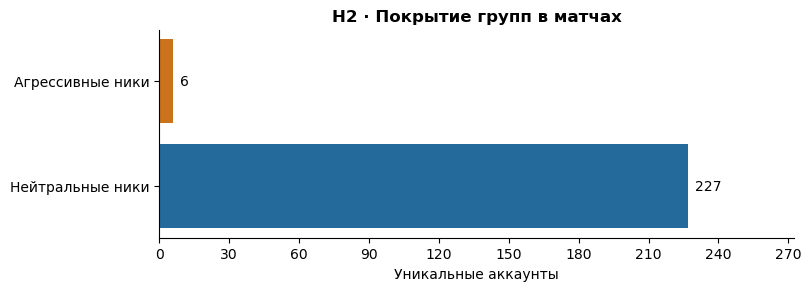

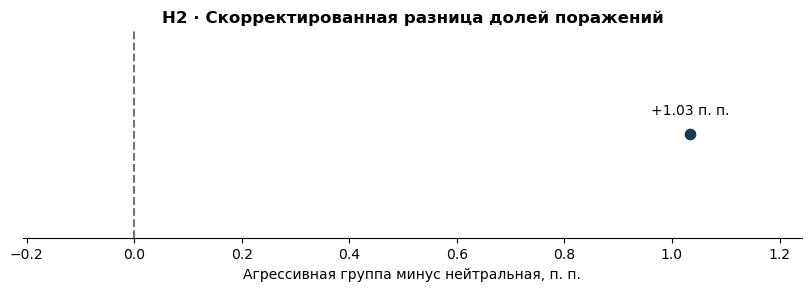

In [11]:
group_labels = {"aggressive": "Агрессивные ники", "neutral": "Нейтральные ники"}
if loss_rates is not None and loss_rates["accounts"].gt(0).any():
    accounts = loss_rates["accounts"].rename(index=group_labels)
    fig, ax = plt.subplots(figsize=(8, 2.8), layout="constrained")
    bars = ax.barh(accounts.index, accounts, color=[amber, blue])
    ax.bar_label(bars, padding=5)
    ax.set(xlabel="Уникальные аккаунты", title="H2 · Покрытие групп в матчах")
    ax.invert_yaxis()
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    ax.margins(x=0.2)
    plt.show()

if h2_effect is None:
    print(h2_note)
else:
    delta = h2_effect["adjusted_difference_pp"]
    low = h2_effect["ci_low_pp"]
    high = h2_effect["ci_high_pp"]
    fig, ax = plt.subplots(figsize=(8, 2.8), layout="constrained")
    if np.isfinite([low, high]).all():
        ax.hlines(0, low, high, color=blue, linewidth=3)
        ax.scatter([low, high], [0, 0], color=blue, marker="|", s=140)
    ax.scatter(delta, 0, color="#183B56", s=55, zorder=3)
    ax.axvline(H2_MIN_DIFFERENCE_PP, color=slate, linestyle="--")
    ax.annotate(f"{delta:+.2f} п. п.", (delta, 0), xytext=(0, 14),
                textcoords="offset points", ha="center")
    ax.set(xlabel="Агрессивная группа минус нейтральная, п. п.",
           title="H2 · Скорректированная разница долей поражений",
           ylim=(-.5, .5), yticks=[])
    ax.spines["left"].set_visible(False)
    ax.margins(x=0.2)
    plt.show()

## 8. Вывод для защиты

Статусы H1 и H2 обновляются после запуска расчётов. Графики выше показывают результаты классификации пилота.

In [12]:
coverage_note = (f"Два прогона MART. {int(counts['Ответы'].sum())} ответов в сводке, "
                 f"{int(states['tagged'].sum())} с тегами, "
                 f"{int(states['unknown'].sum())} со статусом unknown, "
                 f"{int(counts['На ручной проверке'].sum())} с флагом ручной проверки.")
display(pd.Series({"Покрытие": coverage_note, "H1 · F1 тегов": h1_note,
                   "H2 · Доля поражений": h2_note}, name="Вывод").to_frame()
        .style.set_properties(**{"text-align": "left", "white-space": "normal"}))

,Вывод
Покрытие,"Два прогона MART. 298 ответов в сводке, 77 с тегами, 25 со статусом unknown, 34 с флагом ручной проверки."
H1 · F1 тегов,У LLM выше F1 по 1 из 5 тегов. Оценено тегов: 3. Критерий H1 на выборке выполнен. Нижняя граница ΔF1 выше нуля по 1 тегам. Эталонная разметка черновая.
H2 · Доля поражений,Скорректированная разница долей поражений: +1.03 п. п. Устойчивый интервал недоступен по числу кластеров или дисперсии. Группы определены по черновой разметке и последнему доступному нику.
